In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

%matplotlib inline

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

DB_USER = 'root'
DB_PASS = '123456'          
DB_HOST = 'localhost'
DB_PORT = '3306'
DB_NAME = 'EAI'

engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4')

TABLE = 'dwd_user_behavior'   

def q(sql):
    return pd.read_sql(sql, con=engine)


In [2]:
BEHAVIOR_CN = {'pv': '浏览', 'cart': '加购', 'fav': '收藏', 'buy': '购买'}
DEDUP = '`是否重复行` = 0'
FULL_DAYS = "`日期` BETWEEN '2024-05-30' AND '2024-06-03'"

In [3]:
funnel = q(f"""
SELECT `行为类型` AS b, COUNT(*) AS 事件数
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `行为类型`
""").set_index('b')
funnel.index = funnel.index.map(BEHAVIOR_CN)
funnel = funnel.reindex(['浏览','加购','收藏','购买'])
funnel['事件级占比%'] = (funnel['事件数'] / funnel.loc['浏览','事件数'] * 100).round(2)
funnel

,事件数,事件级占比%
b,,
浏览,664369,100.00
加购,42696,6.43
收藏,20601,3.10
购买,14571,2.19


用户级覆盖（去重后）：
浏览用户    10671
加购用户     7404
收藏用户     3488
购买用户     6110

覆盖率口径 浏览→购买：57.3%
严格口径   浏览→购买：56.8%  ← 主口径
（两口径相差 47 个「没浏览直接买」的用户）
加购→购买：82.5%　购物车放弃率：17.5%


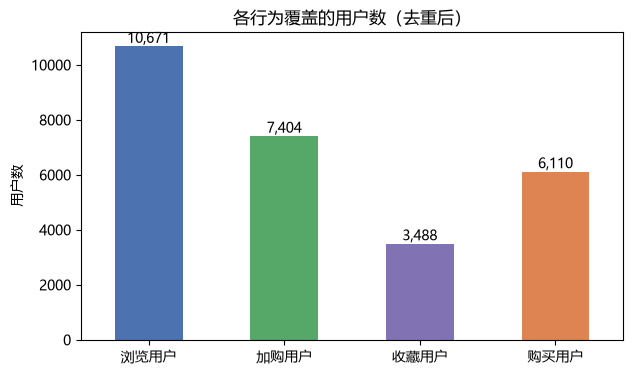

In [4]:
uf = q(f"""
SELECT
  COUNT(DISTINCT CASE WHEN `行为类型`='pv'   THEN `用户ID` END) AS 浏览用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='cart' THEN `用户ID` END) AS 加购用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='fav'  THEN `用户ID` END) AS 收藏用户,
  COUNT(DISTINCT CASE WHEN `行为类型`='buy'  THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP}
""").iloc[0]

strict = q(f"""
SELECT COUNT(*) AS 既浏览又购买用户 FROM (
  SELECT `用户ID` FROM `{TABLE}` WHERE {DEDUP} AND `行为类型` IN ('pv','buy')
  GROUP BY `用户ID`
  HAVING SUM(`行为类型`='pv') > 0 AND SUM(`行为类型`='buy') > 0
) t
""").iloc[0, 0]

print("用户级覆盖（去重后）：")
print(uf.to_string())
print()
print("覆盖率口径 浏览→购买：%.1f%%" % (uf['购买用户']/uf['浏览用户']*100))
print("严格口径   浏览→购买：%.1f%%  ← 主口径" % (strict/uf['浏览用户']*100))
print("（两口径相差 %d 个「没浏览直接买」的用户）" % (uf['购买用户'] - strict))
print("加购→购买：%.1f%%　购物车放弃率：%.1f%%"
      % (uf['购买用户']/uf['加购用户']*100, (1 - uf['购买用户']/uf['加购用户'])*100))

ax = uf.plot.bar(color=['#4C72B0','#55A868','#8172B3','#DD8452'], figsize=(7,4), rot=0)
ax.set_title('各行为覆盖的用户数（去重后）')
ax.set_ylabel('用户数')
for i, v in enumerate(uf):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.show()

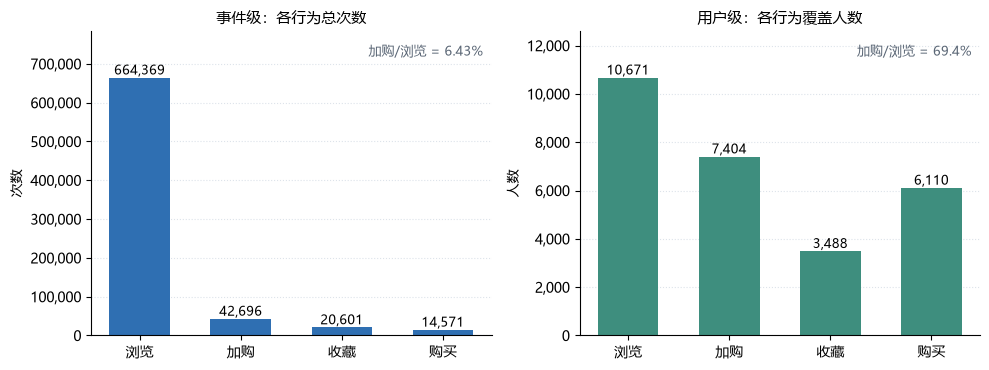

In [5]:
ev = funnel['事件数']
uv = pd.Series({'浏览': uf['浏览用户'], '加购': uf['加购用户'],
                '收藏': uf['收藏用户'], '购买': uf['购买用户']})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

for ax, s, color, title in [(axes[0], ev, '#2F6FB2', '事件级：各行为总次数'),
                            (axes[1], uv, '#3E8E7E', '用户级：各行为覆盖人数')]:
    bars = ax.bar(s.index, s.values, color=color, width=0.6)
    for r, v in zip(bars, s.values):
        ax.text(r.get_x() + r.get_width() / 2, v, f'{v:,}',
                ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, s.values.max() * 1.18)
    ax.grid(axis='y', ls=':', color='#DDE3EA')
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{int(v):,}'))
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

axes[0].set_ylabel('次数')
axes[1].set_ylabel('人数')
axes[0].text(0.98, 0.92, '加购/浏览 = %.2f%%' % funnel.loc['加购', '事件级占比%'],
             transform=axes[0].transAxes, fontsize=9, color='#5A6675', ha='right')
axes[1].text(0.98, 0.92, '加购/浏览 = %.1f%%' % (uv['加购'] / uv['浏览'] * 100),
             transform=axes[1].transAxes, fontsize=9, color='#5A6675', ha='right')

plt.tight_layout()
plt.show()

In [6]:
cat = q(f"""
SELECT `基础品类`,
       COUNT(DISTINCT CASE WHEN `行为类型`='pv'   THEN `用户ID` END) AS 浏览用户,
       COUNT(DISTINCT CASE WHEN `行为类型`='cart' THEN `用户ID` END) AS 加购用户,
       COUNT(DISTINCT CASE WHEN `行为类型`='buy'  THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP}
GROUP BY `基础品类`
""")

cat['浏览→购买%'] = (cat['购买用户'] / cat['浏览用户'].replace(0, np.nan) * 100).round(2)
cat['加购→购买%'] = (cat['购买用户'] / cat['加购用户'].replace(0, np.nan) * 100).round(2)
cat = cat.replace([np.inf, -np.inf], np.nan)

print("=== 高流量低转化（浏览用户>=3000，按浏览→购买率升序）===")
display(cat.query('浏览用户 >= 3000').sort_values('浏览→购买%').head(10)
        [['基础品类','浏览用户','购买用户','浏览→购买%','加购→购买%']])

print("=== 高转化低流量（浏览用户 300~3000，按浏览→购买率降序）===")
display(cat.query('300 <= 浏览用户 < 3000').sort_values('浏览→购买%', ascending=False).head(10)
        [['基础品类','浏览用户','购买用户','浏览→购买%','加购→购买%']])

print("=== 购物车放弃率最高（加购用户>=200，按加购→购买率升序）===")
display(cat.query('加购用户 >= 200').sort_values('加购→购买%').head(10)
        [['基础品类','加购用户','购买用户','加购→购买%']])


=== 高流量低转化（浏览用户>=3000，按浏览→购买率升序）===


,基础品类,浏览用户,购买用户,浏览→购买%,加购→购买%
240,耳机,3349,78,2.33,14.36
3,LED台灯,3043,75,2.46,15.56
273,迷你蓝牙音箱,3090,80,2.59,16.88
14,中性笔,3390,119,3.51,23.15
10,USB风扇,3733,166,4.45,22.02
95,手机壳,4467,240,5.37,26.67
116,数据线,3696,216,5.84,26.09


=== 高转化低流量（浏览用户 300~3000，按浏览→购买率降序）===


,基础品类,浏览用户,购买用户,浏览→购买%,加购→购买%
4,Lightning转接头,321,65,20.25,141.30
156,桌游卡牌,644,123,19.10,121.78
25,修正带,427,72,16.86,101.41
231,美容面膜刷,305,50,16.39,111.11
184,瑜伽眼罩,374,60,16.04,85.71
214,移动电源,525,82,15.62,83.67
78,干燥剂,804,125,15.55,82.78
52,回形针,840,127,15.12,81.41
111,指甲油,1420,207,14.58,66.56
250,茶包,1627,236,14.51,67.24


=== 购物车放弃率最高（加购用户>=200，按加购→购买率升序）===


,基础品类,加购用户,购买用户,加购→购买%
240,耳机,543,78,14.36
3,LED台灯,482,75,15.56
122,方便面,206,33,16.02
273,迷你蓝牙音箱,474,80,16.88
162,梳子,249,48,19.28
10,USB风扇,754,166,22.02
14,中性笔,514,119,23.15
44,厨房开瓶器,371,95,25.61
116,数据线,828,216,26.09
289,面膜,301,80,26.58


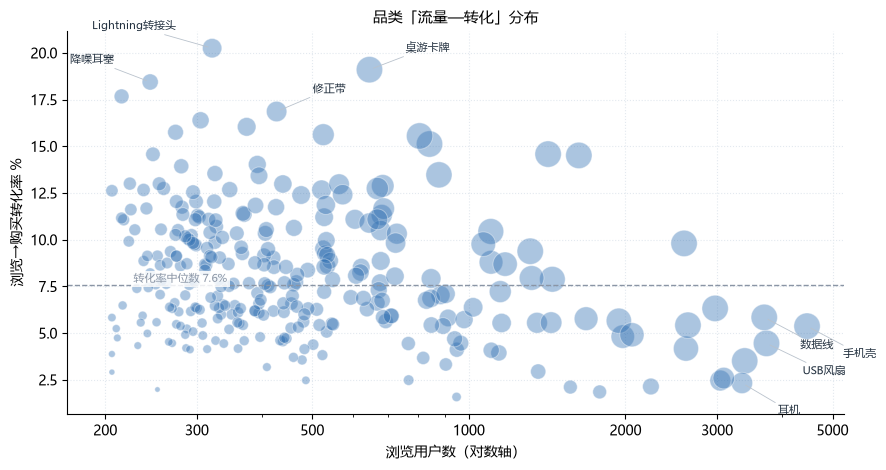

In [7]:
sc = cat.dropna(subset=['浏览用户', '浏览→购买%']).query('浏览用户 >= 200').copy()

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(sc['浏览用户'], sc['浏览→购买%'],
           s=sc['购买用户'].clip(lower=3, upper=120) * 3,
           color='#2F6FB2', alpha=0.4, edgecolor='white', linewidth=0.7)

med = sc['浏览→购买%'].median()
ax.axhline(med, color='#8A95A5', ls='--', lw=1)
ax.text(sc['浏览用户'].min() * 1.1, med, '转化率中位数 %.1f%%' % med,
        fontsize=8, color='#8A95A5', va='bottom',
        bbox=dict(fc='white', ec='none', alpha=0.85, pad=1.5))

# 只标注「流量最大」「转化最高」各 5 个；标签朝四角外推并用细引线连回原点
mark = pd.concat([sc.nlargest(5, '浏览用户'), sc.nlargest(5, '浏览→购买%')]) \
         .drop_duplicates(subset='基础品类').reset_index(drop=True)
mx, my = sc['浏览用户'].median(), sc['浏览→购买%'].median()
picked = []          # 位置太近的标签只留一个，避免互相压字
for _, r in mark.iterrows():
    if any(abs(np.log10(r['浏览用户']) - np.log10(o['浏览用户'])) < 0.06
           and abs(r['浏览→购买%'] - o['浏览→购买%']) < 1.2 for o in picked):
        continue
    picked.append(r)
    dx = 26 if r['浏览用户'] > mx else -26
    dy = 16 if r['浏览→购买%'] > my else -20
    ax.annotate(r['基础品类'], (r['浏览用户'], r['浏览→购买%']),
                textcoords='offset points', xytext=(dx, dy),
                ha='left' if dx > 0 else 'right', va='center',
                fontsize=8, color='#22303F',
                arrowprops=dict(arrowstyle='-', color='#B9C2CC', lw=0.6,
                                shrinkA=0, shrinkB=3))

ax.set_xscale('log')
ticks = [t for t in (100, 200, 300, 500, 1000, 2000, 3000, 5000)
         if sc['浏览用户'].min() * 0.8 <= t <= sc['浏览用户'].max() * 1.25]
ax.xaxis.set_major_locator(plt.FixedLocator(ticks))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{int(v)}'))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(sc['浏览用户'].min() * 0.82, sc['浏览用户'].max() * 1.18)
ax.set_xlabel('浏览用户数（对数轴）')
ax.set_ylabel('浏览→购买转化率 %')
ax.set_title('品类「流量—转化」分布', fontsize=11)
ax.grid(ls=':', color='#E3E9EF')
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

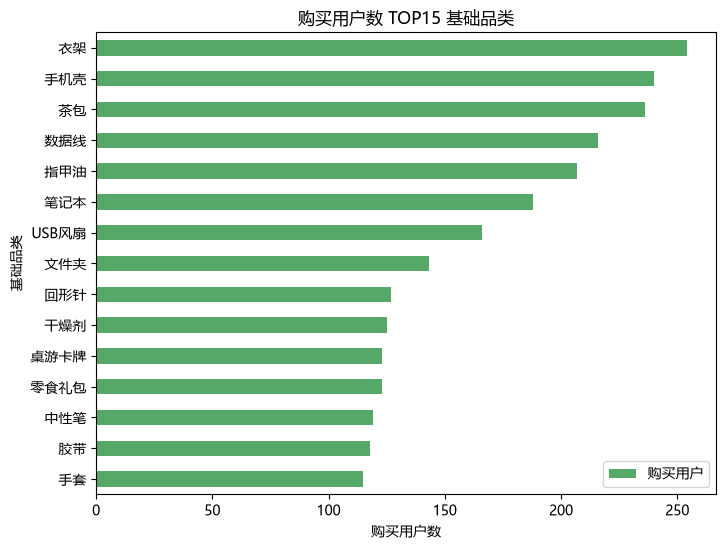

In [8]:
top15 = cat.nlargest(15, '购买用户').sort_values('购买用户')
ax = top15.plot.barh(x='基础品类', y='购买用户', color='#55A868', figsize=(8,6))
ax.set_title('购买用户数 TOP15 基础品类')
ax.set_xlabel('购买用户数')
plt.show()

In [9]:
users = q(f"""
SELECT `用户ID`,
       SUM(CASE WHEN `行为类型`='buy'  THEN 1 ELSE 0 END) AS 购买次数,
       SUM(CASE WHEN `行为类型`='pv'   THEN 1 ELSE 0 END) AS 浏览次数,
       SUM(CASE WHEN `行为类型`='cart' THEN 1 ELSE 0 END) AS 加购次数,
       COUNT(DISTINCT `基础品类`) AS 品类数,
       COUNT(DISTINCT `日期`)     AS 活跃天数
FROM `{TABLE}` WHERE {DEDUP}
GROUP BY `用户ID`
""")
users['购买频次档'] = pd.cut(users['购买次数'], bins=[-1, 0, 1, 2, float('inf')],
                            labels=['0次', '1次', '2次', '3+次'])

tier = users.groupby('购买频次档', observed=True).agg(
    用户数=('用户ID', 'count'),
    人均浏览=('浏览次数', 'median'),
    人均加购=('加购次数', 'median'),
    人均品类=('品类数', 'median'),
    人均活跃天数=('活跃天数', 'median'),
)
tier


,用户数,人均浏览,人均加购,人均品类,人均活跃天数
购买频次档,,,,,
0次,4629,35.0,1.0,13.0,5.0
1次,2691,43.0,2.0,15.0,5.0
2次,1533,51.0,3.0,17.0,6.0
3+次,1886,66.0,4.0,21.0,6.0


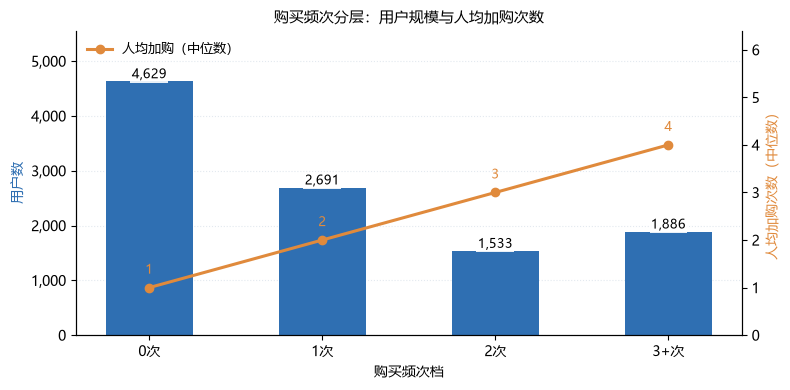

In [10]:
x = tier.index.astype(str)
fig, ax1 = plt.subplots(figsize=(8, 4))

bars = ax1.bar(x, tier['用户数'], color='#2F6FB2', width=0.5, zorder=2)
for r, v in zip(bars, tier['用户数']):
    ax1.text(r.get_x() + r.get_width() / 2, v, f'{v:,}',
             ha='center', va='bottom', fontsize=9, zorder=3,
             bbox=dict(fc='white', ec='none', alpha=0.9, pad=1))
ax1.set_ylim(0, tier['用户数'].max() * 1.20)
ax1.set_xlabel('购买频次档')
ax1.set_ylabel('用户数', color='#2F6FB2')
ax1.grid(axis='y', ls=':', color='#E3E9EF')
ax1.set_axisbelow(True)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{int(v):,}'))

ax2 = ax1.twinx()
ax2.plot(x, tier['人均加购'], color='#E08A3C', marker='o', ms=6, lw=2.2,
         label='人均加购（中位数）', zorder=4)
for i, v in enumerate(tier['人均加购']):
    ax2.annotate(f'{v:g}', (i, v), textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=9, color='#E08A3C')
ax2.set_ylim(0, tier['人均加购'].max() * 1.6)
ax2.set_ylabel('人均加购次数（中位数）', color='#E08A3C')
ax2.legend(loc='upper left', frameon=False, fontsize=9)

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_title('购买频次分层：用户规模与人均加购次数', fontsize=11)
plt.tight_layout()
plt.show()

In [11]:
faces = q(f"""
SELECT `人群标签`, COUNT(DISTINCT `用户ID`) AS 用户数
FROM `{TABLE}` GROUP BY `人群标签` HAVING 用户数 >= 50 ORDER BY 用户数 DESC
""")
top_faces = faces['人群标签'].tolist()
print("人数>=50 的人群：", len(top_faces), "个；", top_faces[:7])


人数>=50 的人群： 9 个； ['大学生', '上班族', '自由职业者', '游戏宅', '农民 / 种植户', '创业者', '互联网从业者']


In [12]:
def pref_index(beh):
    fc = q(f"""
    SELECT `人群标签` AS tag, `基础品类` AS cat, COUNT(DISTINCT `用户ID`) AS n_user
    FROM `{TABLE}` WHERE {DEDUP} AND `行为类型` = '{beh}' GROUP BY tag, cat
    """)
    SHRINK = 20
    cat_total = fc.groupby('cat')['n_user'].sum()
    face_total = fc.groupby('tag')['n_user'].sum()
    p_cat = cat_total / cat_total.sum()
    fc['偏好指数'] = ((fc['n_user'] + SHRINK * fc['cat'].map(p_cat))
                     / (fc['tag'].map(face_total) + SHRINK)
                     / fc['cat'].map(p_cat)).round(2)
    return fc

pref_buy = pref_index('buy')   # 购买偏好（选品/备货）
pref_pv  = pref_index('pv')    # 浏览偏好（拉新/兴趣）


In [13]:
print("=== 购买偏好 TOP（主群体，单元格样本>=30）===")
display(pref_buy[(pref_buy['tag'].isin(top_faces[:7])) & (pref_buy['n_user'] >= 30)]
        .sort_values('偏好指数', ascending=False)
        .groupby('tag', group_keys=False).head(5)[['tag','cat','n_user','偏好指数']])

print("=== 浏览偏好 TOP（主群体，单元格样本>=30）===")
display(pref_pv[(pref_pv['tag'].isin(top_faces[:7])) & (pref_pv['n_user'] >= 30)]
        .sort_values('偏好指数', ascending=False)
        .groupby('tag', group_keys=False).head(5)[['tag','cat','n_user','偏好指数']])


=== 购买偏好 TOP（主群体，单元格样本>=30）===


,tag,cat,n_user,偏好指数
3392,自由职业者,USB风扇,37,1.66
2754,游戏宅,文件夹,31,1.58
1701,大学生,手机壳,45,1.35
1098,农民 / 种植户,茶包,33,1.25
3476,自由职业者,手机壳,38,1.18
2746,游戏宅,指甲油,31,1.09
1102,农民 / 种植户,衣架,31,1.09
1716,大学生,指甲油,30,1.05
1849,大学生,衣架,37,1.05
2730,游戏宅,手机壳,34,1.04


=== 浏览偏好 TOP（主群体，单元格样本>=30）===


,tag,cat,n_user,偏好指数
4158,创业者,便携式WiFi热点,35,1.77
6200,大学生,智能睡眠眼罩,41,1.55
1240,互联网从业者,仿真花,47,1.50
3814,农民 / 种植户,瑜伽袜,51,1.49
1425,互联网从业者,白板笔,32,1.45
3863,农民 / 种植户,美甲灯,72,1.44
1497,互联网从业者,迷你麦克风,30,1.43
3861,农民 / 种植户,美甲亮片,60,1.43
15778,自由职业者,多功能读卡器,66,1.41
11977,游戏宅,汽车空气净化器,41,1.41


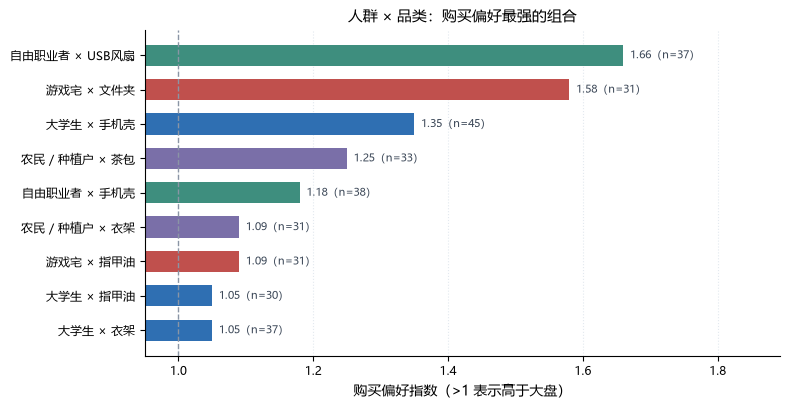

In [14]:
pr = pref_buy[pref_buy['tag'].isin(top_faces[:7]) & (pref_buy['n_user'] >= 30)]
top_pref = pr.nlargest(9, '偏好指数').iloc[::-1]

palette = ['#2F6FB2', '#E08A3C', '#3E8E7E', '#C0504D', '#7A6FA8', '#5B8C5A', '#B08968']
tag_color = {t: palette[i % len(palette)] for i, t in enumerate(top_faces[:7])}

labels = top_pref['tag'] + ' × ' + top_pref['cat']
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels, top_pref['偏好指数'],
        color=[tag_color[t] for t in top_pref['tag']], height=0.62)
for i, (v, n) in enumerate(zip(top_pref['偏好指数'], top_pref['n_user'])):
    ax.text(v + 0.01, i, f'{v:.2f}（n={n}）', va='center', fontsize=8, color='#3C4858')
ax.axvline(1, color='#8A95A5', ls='--', lw=1)
ax.set_xlim(0.95, top_pref['偏好指数'].max() * 1.14)
ax.set_xlabel('购买偏好指数（>1 表示高于大盘）')
ax.set_title('人群 × 品类：购买偏好最强的组合', fontsize=11)
ax.grid(axis='x', ls=':', color='#E3E9EF')
ax.set_axisbelow(True)
ax.tick_params(labelsize=8.5)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
gender = q(f"""
SELECT `性别`, COUNT(DISTINCT `用户ID`) AS 用户数,
       COUNT(DISTINCT CASE WHEN `行为类型`='buy' THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `性别`
""")
gender

gender_cat = q(f"""
SELECT `性别`, `基础品类`, COUNT(DISTINCT CASE WHEN `行为类型`='buy' THEN `用户ID` END) AS 购买用户
FROM `{TABLE}` WHERE {DEDUP} GROUP BY `性别`, `基础品类`
""")

g = gender_cat.copy()
sex_total = g.groupby('性别')['购买用户'].transform('sum')
cat_total = g.groupby('基础品类')['购买用户'].transform('sum')
all_total = g['购买用户'].sum()
g['lift'] = ((g['购买用户'] / sex_total) / (cat_total / all_total)).round(2)

for s in ['男', '女']:
    print(f"=== {s} 规模榜 TOP8（按购买用户数）===")
    display(gender_cat.query("性别 == @s").nlargest(8, '购买用户'))
    print(f"=== {s} 偏好榜 TOP8（按 lift，购买用户>=30）===")
    display(g.query("性别 == @s and 购买用户 >= 30").nlargest(8, 'lift')[['基础品类','购买用户','lift']])


=== 男 规模榜 TOP8（按购买用户数）===


,性别,基础品类,购买用户
556,男,衣架,119
396,男,手机壳,105
551,男,茶包,100
412,男,指甲油,93
417,男,数据线,89
311,男,USB风扇,81
519,男,笔记本,75
420,男,文件夹,63


=== 男 偏好榜 TOP8（按 lift，购买用户>=30）===


,基础品类,购买用户,lift
517,空气清新剂,43,1.41
354,围巾,35,1.28
460,桌面收纳架,30,1.21
470,洗衣袋,38,1.18
544,耳钉,37,1.17
594,鞋垫,33,1.15
311,USB风扇,81,1.14
339,化妆刷,55,1.13


=== 女 规模榜 TOP8（按购买用户数）===


,性别,基础品类,购买用户
250,女,茶包,136
95,女,手机壳,135
255,女,衣架,135
116,女,数据线,127
111,女,指甲油,114
218,女,笔记本,113
10,女,USB风扇,85
119,女,文件夹,80


=== 女 偏好榜 TOP8（按 lift，购买用户>=30）===


,基础品类,购买用户,lift
23,保温杯,39,1.31
203,相册,32,1.22
65,宠物喂食器,31,1.21
284,降噪耳塞,31,1.21
106,折叠水壶,43,1.19
114,收纳盒,44,1.18
72,小型玩偶,30,1.17
179,火柴盒,49,1.17


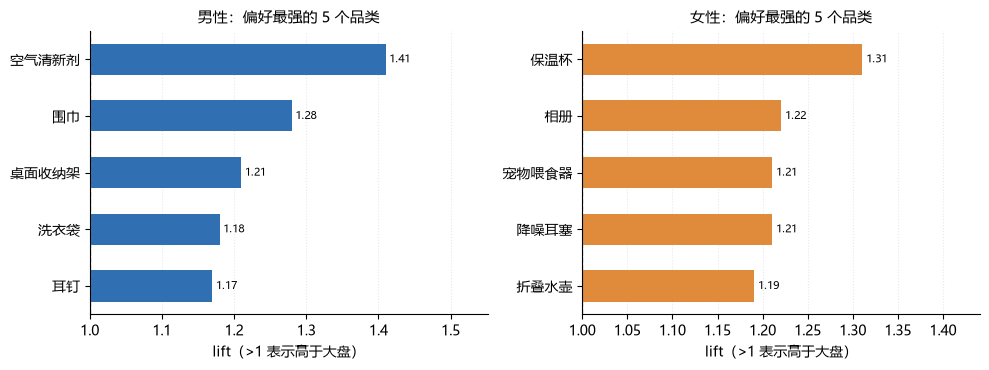

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

for ax, s, color in zip(axes, ['男', '女'], ['#2F6FB2', '#E08A3C']):
    d = g.query("性别 == @s and 购买用户 >= 30").nlargest(5, 'lift').iloc[::-1]
    ax.barh(d['基础品类'], d['lift'], color=color, height=0.55)
    for i, v in enumerate(d['lift']):
        ax.text(v + 0.005, i, f'{v:.2f}', va='center', fontsize=8)
    ax.axvline(1, color='#8A95A5', ls='--', lw=1)
    ax.set_xlim(1, d['lift'].max() * 1.10)
    ax.set_title(f'{s}性：偏好最强的 5 个品类', fontsize=11)
    ax.set_xlabel('lift（>1 表示高于大盘）')
    ax.grid(axis='x', ls=':', color='#E3E9EF')
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
hour = q(f"""
SELECT `小时`, COUNT(*) AS 行为数,
       SUM(CASE WHEN `行为类型`='buy' THEN 1 ELSE 0 END) AS 购买数
FROM `{TABLE}` WHERE {DEDUP}
GROUP BY `小时`
ORDER BY `小时`
""")
hour['购买率%'] = (hour['购买数'] / hour['行为数'] * 100).round(2)
hour[['小时', '行为数', '购买数', '购买率%']]


,小时,行为数,购买数,购买率%
0,0,39021,1002.0,2.57
1,1,39011,789.0,2.02
2,2,39566,897.0,2.27
3,3,37083,827.0,2.23
4,4,34109,735.0,2.15
5,5,37665,777.0,2.06
6,6,49258,869.0,1.76
7,7,58890,949.0,1.61
8,8,66014,1081.0,1.64
9,9,55464,872.0,1.57


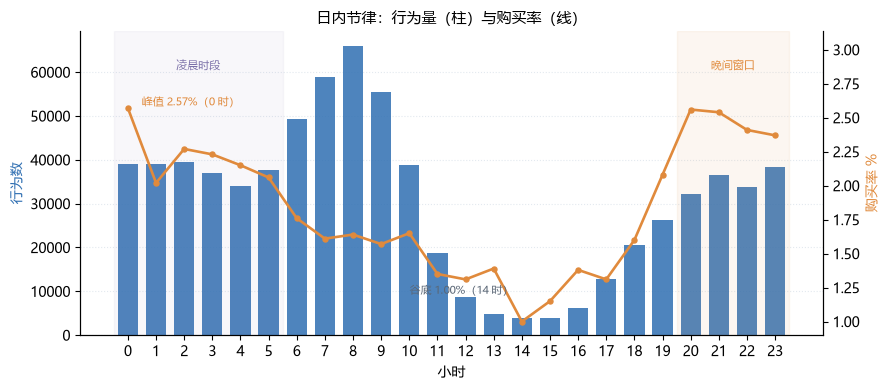

In [18]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax1.bar(hour['小时'], hour['行为数'], color='#2F6FB2', alpha=0.85, width=0.72)
ax1.set_xticks(range(0, 24))
ax1.set_xlabel('小时')
ax1.set_ylabel('行为数', color='#2F6FB2')
ax1.grid(axis='y', ls=':', color='#E3E9EF')
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(hour['小时'], hour['购买率%'], color='#E08A3C', marker='o', ms=3.6, lw=1.9)
ax2.set_ylabel('购买率 %', color='#E08A3C')
ax2.set_ylim(0.9, hour['购买率%'].max() * 1.22)

ax2.axvspan(19.5, 23.5, color='#E08A3C', alpha=0.07, zorder=0)
ax2.axvspan(-0.5, 5.5, color='#7A6FA8', alpha=0.05, zorder=0)
_top = hour['购买率%'].max() * 1.14
ax2.text(21.5, _top, '晚间窗口', fontsize=8, color='#E08A3C', ha='center', va='top', zorder=5)
ax2.text(2.5, _top, '凌晨时段', fontsize=8, color='#7A6FA8', ha='center', va='top', zorder=5)

peak = hour.loc[hour['购买率%'].idxmax()]
ax2.annotate('峰值 %.2f%%（%d 时）' % (peak['购买率%'], peak['小时']),
             (peak['小时'], peak['购买率%']), textcoords='offset points',
             xytext=(10, 2), ha='left', fontsize=8, color='#E08A3C')
low = hour.loc[hour['购买率%'].idxmin()]
ax2.annotate('谷底 %.2f%%（%d 时）' % (low['购买率%'], low['小时']),
             (low['小时'], low['购买率%']), textcoords='offset points',
             xytext=(-6, 20), ha='right', fontsize=8, color='#5A6675')

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_title('日内节律：行为量（柱）与购买率（线）', fontsize=11)
plt.tight_layout()
plt.show()

In [19]:
week = q(f"""
SELECT `星期`, COUNT(*) AS 行为数,
       SUM(CASE WHEN `行为类型`='buy' THEN 1 ELSE 0 END) AS 购买数
FROM `{TABLE}` WHERE {DEDUP} AND {FULL_DAYS}
GROUP BY `星期`
""").set_index('星期').reindex(['周四','周五','周六','周日','周一'])
week['购买率%'] = (week['购买数'] / week['行为数'] * 100).round(2)
week[['行为数','购买数','购买率%']]

,行为数,购买数,购买率%
星期,,,
周四,106367,2247.0,2.11
周五,110154,2395.0,2.17
周六,112416,2233.0,1.99
周日,128970,2415.0,1.87
周一,153002,2835.0,1.85


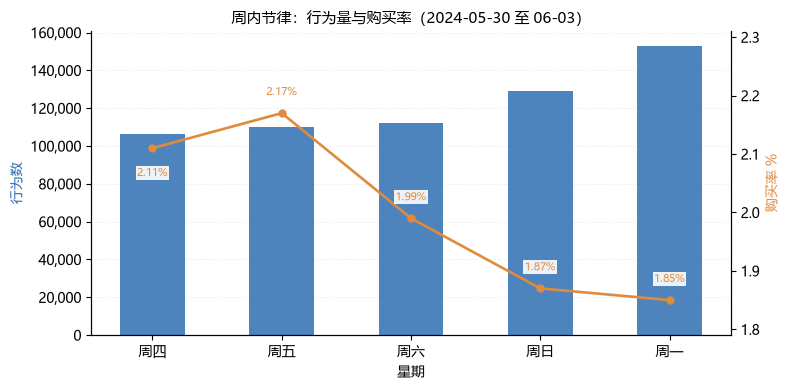

In [20]:
wk = week.dropna(subset=['行为数'])
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.bar(wk.index, wk['行为数'], color='#2F6FB2', alpha=0.85, width=0.5)
ax1.set_xlabel('星期')
ax1.set_ylabel('行为数', color='#2F6FB2')
ax1.grid(axis='y', ls=':', color='#E3E9EF')
ax1.set_axisbelow(True)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{int(v):,}'))

ax2 = ax1.twinx()
ax2.plot(wk.index, wk['购买率%'], color='#E08A3C', marker='o', ms=5, lw=1.9)
rates = wk['购买率%'].tolist()
ax2.set_ylim(min(rates) - 0.06, max(rates) + 0.14)
for i, v in enumerate(rates):
    rising = i + 1 < len(rates) and rates[i + 1] > v
    dy = -20 if rising else 13
    ax2.annotate(f'{v:.2f}%', (i, v), textcoords='offset points', xytext=(0, dy),
                 ha='center', fontsize=8, color='#E08A3C',
                 bbox=dict(fc='white', ec='none', alpha=0.9, pad=1))
ax2.set_ylabel('购买率 %', color='#E08A3C')

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_title('周内节律：行为量与购买率（2024-05-30 至 06-03）', fontsize=11)
plt.tight_layout()
plt.show()

In [21]:
rep = q(f"""
SELECT
  COUNT(DISTINCT CASE WHEN 购买次数 > 1 THEN `用户ID` END) AS 复购用户数,
  COUNT(DISTINCT `用户ID`)                                   AS 购买用户数,
  SUM(CASE WHEN 购买次数 > 1 THEN 1 ELSE 0 END)              AS 复购组合数,
  COUNT(*)                                                   AS 购买组合数
FROM (
  SELECT `用户ID`, `商品ID`, COUNT(*) AS 购买次数
  FROM `{TABLE}` WHERE {DEDUP} AND `行为类型`='buy'
  GROUP BY `用户ID`, `商品ID`
) t
""").iloc[0]

print("窗口内用户级复购率：%.1f%%" % (rep['复购用户数'] / rep['购买用户数'] * 100))
print("窗口内组合级复购率：%.1f%%" % (rep['复购组合数'] / rep['购买组合数'] * 100))


窗口内用户级复购率：6.8%
窗口内组合级复购率：3.7%
